# Morphing facial con modelos generativos
Visión por Computador · CDIA · ETSISI-UPM

**Objetivo:** transformar progresivamente un rostro en otro y comparar, bajo las mismas condiciones (mismos pares, mismo número de fotogramas, misma resolución), tres enfoques: **morphing clásico**, **VAE convolucional** y **DCGAN**.

| Enfoque | Idea | Prioridad |
| --- | --- | --- |
| Clásico | landmarks + Delaunay + warping afín | Imprescindible |
| VAE | interpolar en el espacio latente | Imprescindible |
| DCGAN | invertir foto real → interpolar $z$ | Si hay tiempo |

**Dataset:** CelebA, 64×64 RGB para VAE y DCGAN; originales en alta resolución para el clásico.

**Descarga del dataset:** [CelebA en Kaggle](https://www.kaggle.com/datasets/jessicali9530/celeba-dataset). Descomprimirlo en `data/` de modo que queden `data/img_align_celeba/img_align_celeba/*.jpg` y los CSV (`list_attr_celeba.csv`, `list_eval_partition.csv`, `list_landmarks_align_celeba.csv`) directamente en `data/`. La carpeta `data/` no se versiona.

In [9]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # antes de importar keras: mismo código en CUDA (Linux/Windows) y MPS (Mac)

import random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import keras

# Dispositivo: se detecta solo, no hay que tocar nada a mano
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
torch.set_default_device(DEVICE)

In [10]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)

In [11]:
ROOT = Path(".")
PROC = ROOT/"data"/"processed"      # PROC/{train,val,test}/{x,attrs,ids}.npy
OUT = ROOT/"outputs"
for d in (PROC, OUT): d.mkdir(parents=True, exist_ok=True)

print(f"Keras {keras.__version__} | backend: {keras.backend.backend()} | dispositivo: {DEVICE}")

Keras 3.12.1 | backend: torch | dispositivo: cuda


## 1. Datos y preprocesamiento

El aprendizaje de los modelos generativos de esta práctica es **no supervisado**: igual que en un autoencoder, no hacen falta etiquetas, solo las muestras (`X_train, X_train`). Las etiquetas de CelebA (sonrisa, gafas...) solo se usan después, en el experimento E.

Pasos comunes a todos los métodos:
1. **Selección, recorte y alineación** de los rostros.
2. **Redimensionado** a 64×64 y **normalización**. El rango depende de la salida del decoder/generador: $[0,1]$ si termina en sigmoide, $[-1,1]$ si termina en `tanh` (como el generador de la DCGAN).
3. **Particiones** train / validación / test. El test no se toca hasta la evaluación final.
4. **Conjunto de evaluación:** 20-30 pares fijos (fáciles y difíciles), iguales para todos los métodos.

> Nota: el preprocesado debe ser idéntico para VAE y DCGAN; si no, la comparación no es justa.

### Decisiones de preprocesamiento (y por qué)

**Origen de los datos.** CelebA alineada (`img_align_celeba`, 202.599 imágenes de **178×218** px) con sus CSV de atributos y particiones. Se descarga en `data/` (no se versiona).

**Recorte del dataset.** Se usan las particiones oficiales, pero solo una muestra aleatoria con `SEED` fija: **60.000 train, 5.000 val y 10.000 test**. Hay que entrenar unos 8 modelos (experimentos A-F y DCGAN) y con 160.000 imágenes cada uno tardaría demasiado, sobre todo sin GPU potente. Con la misma semilla, todos obtenemos las mismas imágenes. Test es mayor porque FID/KID son más estables con más muestras.

**Recorte previo: caja `(15, 40, 163, 188)` = cuadrado de 148×148.**
- El original no es cuadrado y contiene pelo, cuello y fondo. Redimensionar la foto entera a 64×64 la deformaría y dejaría la cara pequeña. Recortando un cuadrado alrededor de la cara, casi todos los píxeles se dedican a rasgos faciales, que es lo que importa en el morphing.
- Horizontalmente está centrada: $(178-148)/2=15$. En vertical se baja 5 px respecto al centro exacto (40 en vez de 35), porque en CelebA la cara queda algo baja. Es la convención habitual con este dataset, no un valor optimizado para el proyecto.

**¿Quedan todas las caras centradas con una caja fija?** Funciona porque CelebA ya está alineada (por ojos y boca). Lo comprobamos con `list_landmarks_align_celeba.csv` (202.599 imágenes), midiendo la posición de cada rasgo dentro de la caja (centro = (74, 74)):

| Rasgo | Posición media (x, y) | Desviación típica |
| --- | --- | --- |
| Ojos | (73,5; 71,2) | 0,4 px en x · 0,8 px en y |
| Boca | (73,4; 112,2) | 0,8 px en x · 1,5 px en y |
| Nariz | (73,1; 95,1) | 6,6 px en x · 4,2 px en y |

- Ojos y boca caen siempre en el mismo sitio (variación de 1-2 px en 148): el eje de la cara está centrado.
- La nariz varía más, pero es esperable: cuando la cabeza gira, se desplaza respecto al eje ojos-boca. Es justo la **pose** que usaremos para clasificar los pares en fáciles y difíciles.
- **Límites:** la escala no se corrige (distancia entre ojos: 38 ± 3 px; en el 2 % de los casos baja de 27 px o sube de 45), así que algunas caras se ven algo más grandes o pequeñas. Y si el alineado original falló (caras muy giradas), la cara quedará descentrada.

**Formato de salida (`data/processed/`).** Una carpeta por partición, con los mismos tres archivos dentro:

```
data/processed/
├── train/   x.npy  attrs.npy  ids.npy   (60.000)  ajustar los pesos
├── val/     x.npy  attrs.npy  ids.npy   (5.000)   vigilar sobreajuste y comparar configuraciones (β, latent_dim...)
└── test/    x.npy  attrs.npy  ids.npy   (10.000)  solo evaluación final; de aquí salen los pares de evaluación
```

- `x.npy`: imágenes `(N, 64, 64, 3)` en `uint8` (0-255); ocupa 4 veces menos que `float32` y vale en cualquier equipo.
- `attrs.npy`: los 40 atributos `(N, 40)` con valores -1/1 (nombres en `ATTR_NAMES`).
- `ids.npy`: nombre del archivo original (p. ej. `000001.jpg`), para recuperar la imagen en alta resolución.
- La fila *i* de los tres archivos de una carpeta es la misma cara.

La **normalización** (a [0,1] o [-1,1]) no se aplica aquí: depende de la última capa de cada modelo (sigmoide en el VAE, `tanh` en la DCGAN) y se hace al cargar los lotes. Si ya existen los `.npy` de una partición, la celda no la repite. **Si cambias `CROP`, `IMG_SIZE` o `N`, borra `data/processed/`** antes de volver a ejecutar.

In [12]:
import pandas as pd
from PIL import Image

IMG_DIR = ROOT/"data"/"img_align_celeba"/"img_align_celeba"
IMG_SIZE = 64
CROP = (15, 40, 163, 188)   # caja 148x148 sobre la imagen alineada de CelebA (178x218): cara sin fondo
N = {"train": 60_000, "val": 5_000, "test": 10_000}   # recorte del dataset (se elige al azar con SEED)

(60000, 64, 64, 3) (5000, 64, 64, 3) (10000, 64, 64, 3) | atributos: 40


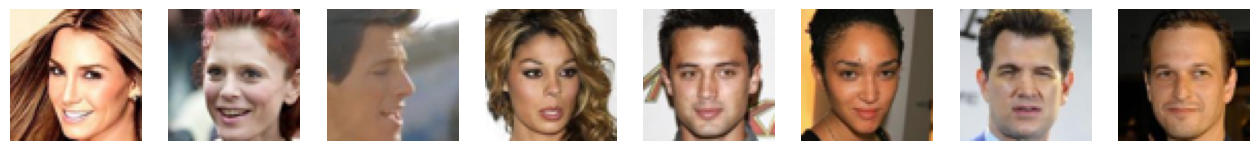

In [13]:
def procesar(path):
    img = Image.open(path).convert("RGB").crop(CROP)
    return np.asarray(img.resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC))

attrs = pd.read_csv(ROOT/"data"/"list_attr_celeba.csv", index_col="image_id")
part  = pd.read_csv(ROOT/"data"/"list_eval_partition.csv", index_col="image_id")["partition"]
ATTR_NAMES = list(attrs.columns)

rng = np.random.default_rng(SEED)
for k, split in enumerate(["train", "val", "test"]):       # 0 / 1 / 2 en list_eval_partition
    d = PROC/split
    ids = part.index[part == k].to_numpy()
    ids = np.sort(rng.choice(ids, N[split], replace=False))    # siempre se consume el rng: la muestra no depende de la caché
    if (d/"x.npy").exists():
        continue                                           # ya procesado: no se repite
    d.mkdir(exist_ok=True)
    np.save(d/"ids.npy", ids)                                  # nombres de archivo (para volver al original)
    np.save(d/"attrs.npy", attrs.loc[ids].to_numpy(np.int8))   # (N, 40) con valores -1 / 1
    np.save(d/"x.npy", np.stack([procesar(IMG_DIR/i) for i in ids]))   # (N, 64, 64, 3) uint8
    print(split, len(ids))

train_x, train_attrs = np.load(PROC/"train"/"x.npy"), np.load(PROC/"train"/"attrs.npy")
val_x,   val_attrs   = np.load(PROC/"val"/"x.npy"),   np.load(PROC/"val"/"attrs.npy")
test_x,  test_attrs  = np.load(PROC/"test"/"x.npy"),  np.load(PROC/"test"/"attrs.npy")
print(train_x.shape, val_x.shape, test_x.shape, "| atributos:", len(ATTR_NAMES))

fig, axs = plt.subplots(1, 8, figsize=(16, 2.2))
for a, im in zip(axs, train_x[:8]):
    a.imshow(im); a.axis("off")
plt.show()

## 2. Morphing clásico (baseline)

Se trabaja directamente sobre píxeles, sin aprendizaje. Para dos imágenes $A$ y $B$ y un parámetro $t\in[0,1]$:

1. **Landmarks y correspondencias** entre ambos rostros (sobre la imagen original).
2. **Triangulación de Delaunay** de los puntos: divide el rostro en triángulos que se corresponden entre $A$ y $B$.
3. **Warping afín local:** cada triángulo se deforma con una transformación afín (6 parámetros) hacia la forma intermedia $P_t = (1-t)P_A + tP_B$.
4. **Mezcla (cross-dissolve)** de las dos imágenes deformadas:
$$I_t = (1-t)\,\text{warp}_A(t) + t\,\text{warp}_B(t)$$
5. Exportar los fotogramas como GIF/vídeo y **reducir a 64×64** para compararlo con VAE y DCGAN.

Aquí la geometría y el color se tratan por separado y de forma explícita, por eso sirve de referencia: conserva bien la estructura pero falla con poses muy distintas.

In [ ]:
# TODO: detección de landmarks y correspondencia entre A y B
# TODO: Delaunay + warping afín por triángulo
# TODO: mezcla -> n_frames fotogramas, reescalado a 64x64, export GIF

## 3. VAE convolucional (núcleo del proyecto)

### 3.1 Del autoencoder al VAE
Un **autoencoder** tiene un **encoder** que comprime la entrada en una representación de baja dimensión (el *cuello de botella*, bottleneck) y un **decoder** que reconstruye la muestra a partir de ella. Se entrena minimizando la diferencia entre entrada y salida (`mean_squared_error`) sin etiquetas. Cuanto más pequeño es el cuello de botella, más compresión y menos calidad; con muy pocas neuronas la red no puede codificar muestras complejas.

La versión **convolucional** sustituye las capas densas por un encoder `Conv2D` + `MaxPooling2D` (o convoluciones con stride) y un decoder con `Conv2DTranspose`, que va recuperando tamaño de mapa y produce imágenes más nítidas con un número de parámetros similar. Una capa final `Conv2D` con 3 filtros devuelve la imagen RGB.

Un autoencoder normal asigna a cada imagen un punto aislado del espacio latente, y los puntos intermedios no tienen por qué decodificarse a nada útil. Eso es un problema para el morphing. El **VAE** corrige esto haciendo que el encoder devuelva una *distribución* en lugar de un punto.

### 3.2 Formulación (extensión de la teoría de autoencoders)
- Encoder: $q_\phi(z|x)=\mathcal N(\mu_\phi(x),\,\sigma^2_\phi(x))$. Salidas: media y varianza (normalmente $\log\sigma^2$).
- **Truco de reparametrización:** $z=\mu+\sigma\odot\varepsilon,\ \varepsilon\sim\mathcal N(0,I)$, para poder retropropagar a través del muestreo.
- Decoder: reconstruye $\hat x = p_\theta(x|z)$.
- Función de pérdida (la del README):
$$\mathcal L = \mathcal L_{recon} + \beta\, D_{KL}\big(q_\phi(z|x)\,\|\,p(z)\big),\qquad p(z)=\mathcal N(0,I)$$
  - $\mathcal L_{recon}$: igual que en el autoencoder (MSE).
  - $D_{KL}$: obliga al espacio latente a ser continuo y centrado, de modo que los puntos intermedios decodifican a rostros plausibles.
  - $\beta$: equilibrio entre ambos términos. $\beta$ alto → latente más regular pero imágenes más borrosas.

### 3.3 Morphing con el VAE
Codificar $A$ y $B$ → obtener $z_A, z_B$ (usar $\mu$) → interpolar → decodificar cada $z_t$:
$$z_t=(1-t)z_A+t z_B \quad\text{(lineal)}$$
Configuración base: `latent_dim=32`, `β=1`. En cada experimento se cambia **un solo factor**.

In [ ]:
# TODO: encoder conv (mu, logvar) + reparametrización + decoder conv
# TODO: pérdida = recon + beta * KL
# TODO: bucle de entrenamiento con validación y curvas de pérdida
# TODO: comprobar reconstrucciones y muestras z ~ N(0, I)
# TODO: función morph(xA, xB, n_frames) en el espacio latente

## 4. DCGAN

### 4.1 GAN
Una GAN tiene dos redes que se entrenan juntas pero por separado:
- **Generador** $G$: parte de un vector aleatorio $z$ (ruido, p. ej. normal) y crea una muestra *fake*.
- **Discriminador** $D$: clasificador binario que distingue muestras reales (etiqueta 1) de generadas (etiqueta 0).

Cada iteración tiene dos fases:
1. **Entrenar $D$** con un lote de imágenes reales (→1) y otro de generadas (→0).
2. **Entrenar $G$** a través del modelo combinado $z\to G\to D$ con $D$ **congelado** (`trainable=False`) y etiquetando lo generado como *real*: $G$ mejora hasta que $D$ lo clasifica como auténtico. Si no se congela $D$, se estaría afinando el discriminador en lugar del generador.

### 4.2 DCGAN
Es la GAN con redes convolucionales:
- **Generador:** `Dense` que reorganiza $z$ en un mapa pequeño → bloques de `UpSampling2D`/`Conv2D` que duplican el tamaño, con `BatchNormalization` y `ReLU`; salida con `tanh`.
- **Discriminador:** `Conv2D` con `stride=2` que reducen el mapa, `LeakyReLU`, `Dropout` (evita que fije detalles) y una neurona final de clasificación binaria.
- `BatchNormalization` y `LeakyReLU` estabilizan el entrenamiento y reducen los *epochs* necesarios.

### 4.3 Vigilar la estabilidad
Curvas de pérdida de $G$ y $D$, muestras generadas cada cierto número de epochs (como el GIF de evolución visto en clase) y detección de *mode collapse* (muchas muestras casi iguales).

### 4.4 Morphing con fotos reales: inversión
La DCGAN no tiene encoder, así que para una foto real $x$ se busca $z^*$ por optimización:
$$z^*=\arg\min_z\ \|G(z)-x\|^2$$
Es el mismo esquema de gradiente que en *neural style transfer*: se fijan los pesos de la red y el que se optimiza por descenso de gradiente es la entrada. Después se interpola entre $z_A^*$ y $z_B^*$ de dos formas:
$$\text{lineal: } z_t=(1-t)z_A+t z_B \qquad \text{SLERP: } z_t=\frac{\sin((1-t)\Omega)}{\sin\Omega}z_A+\frac{\sin(t\Omega)}{\sin\Omega}z_B,\ \ \Omega=\arccos\frac{z_A\cdot z_B}{\|z_A\|\|z_B\|}$$
Si la inversión no reconstruye bien, se interpola entre dos rostros generados por la propia GAN y se reportan aparte.

In [ ]:
# TODO: generador y discriminador convolucionales (64x64)
# TODO: entrenamiento alternado D / G, curvas de pérdida y muestras periódicas
# TODO: inversión de foto real (optimizar z con G fijo)
# TODO: interpolación lineal y SLERP -> fotogramas

## 5. Experimentos

Se varía **un solo factor** cada vez y se usan siempre los mismos pares.

| ID | Experimento | Teoría de apoyo | Prioridad |
| --- | --- | --- | --- |
| A | Interpolación lineal vs SLERP | Los latentes $\mathcal N(0,I)$ de alta dimensión se concentran en una cáscara; la recta pasa por zonas de norma menor. SLERP mantiene la norma. | Imprescindible |
| B | `latent_dim` 16 / 32 / 64 | Tamaño del cuello de botella: menos dimensiones → más compresión y menos calidad | Si hay tiempo |
| C | $\beta$ = 0,5 / 1 / 2 | Compromiso reconstrucción ↔ regularidad del latente | Imprescindible |
| D | VAE vs clásico (mismos pares) | Comparar contra el baseline | Imprescindible |
| E | Direcciones semánticas | $d_{attr}=\bar z_{con}-\bar z_{sin}$; mover $z$ por $d$ y ver si solo cambia ese rasgo | Muy recomendable |
| F | Pérdida perceptual | Ver abajo | Muy recomendable |

### Pérdida perceptual (F)
En *neural style transfer* se usa una **VGG19 preentrenada en ImageNet** como extractor de características: las primeras capas captan texturas y trazos, las últimas el contenido. La *content loss* compara mapas de activación de la imagen original y la generada, en lugar de píxeles:
$$\mathcal L_{perc}=\big\|\phi_l(x)-\phi_l(\hat x)\big\|^2$$
Se sustituye (o se suma a) el MSE del VAE. Se espera mayor nitidez, porque el MSE favorece reconstrucciones promediadas y borrosas. Para estilo se usaría la matriz de Gram, pero aquí solo interesa la parte de contenido.

In [ ]:
# TODO: A) lineal vs SLERP sobre los pares fijos
# TODO: C) entrenar con beta in {0.5, 1, 2}
# TODO: D) clásico vs VAE (vs DCGAN si hay)
# TODO: E) direcciones de atributos (media con - media sin) y recorridos
# TODO: F) pérdida perceptual (VGG/LPIPS) vs VAE base
# TODO: B) latent_dim in {16, 32, 64} (si hay tiempo)

## 6. Evaluación

Se evalúan por separado la calidad de los fotogramas, la continuidad de la transición y la conservación de la identidad. Se mantienen constantes pares, número de fotogramas y condiciones; se reporta **media ± desviación típica** sobre los pares.

| Métrica | Mide | Limitación |
| --- | --- | --- |
| MSE y SSIM | Calidad de reconstrucción | Penalizan reconstrucciones plausibles pero distintas |
| FID o KID | Calidad global de lo generado | No mide la calidad del morphing |
| Curva de identidad | Similitud de cada fotograma con origen y destino (embeddings faciales) | Estos modelos usan más resolución: se reescala y se declara |
| Suavidad temporal | Cambio entre fotogramas consecutivos, artefactos | Continuidad ≠ realismo |
| Coste | Tiempos de entrenamiento/generación, hardware | Depende del equipo |

**Lectura esperada de la curva de identidad:** la similitud con el origen debe bajar y la del destino subir de forma monótona y suave; el cruce marca el punto en que la identidad cambia.

In [ ]:
# TODO: MSE / SSIM sobre reconstrucciones
# TODO: FID o KID (una de las dos)
# TODO: curva de identidad (embeddings faciales, declarar el reescalado)
# TODO: suavidad temporal entre fotogramas consecutivos
# TODO: tiempos y hardware
# TODO: tabla final (media ± std por método) y secuencias comparativas

## 7. Conclusiones y limitaciones

- ¿Qué aporta cada enfoque en calidad visual, identidad, continuidad y coste?
- ¿Cuándo y por qué falla cada uno (poses difíciles, borrosidad del VAE, inestabilidad o inversión de la DCGAN)?
- Limitaciones declaradas: resolución 64×64, comparación no equivalente si la hay, dependencia del hardware.

> El criterio de éxito es una comparación rigurosa y reproducible, no la animación más atractiva.